# Week 10 Jupyter Notebook – K-Means and Silhouette Score
## Exploring Borrower Groups with Unsupervised Learning

### Project Overview

For Week 10, I am using K-Means clustering to see whether borrowers form distinct groups based on their financial and loan characteristics. Unlike Weeks 4–9, clustering does not predict loan default directly. I excluded loan status from the clustering inputs and used it afterward to describe the groups.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score, adjusted_rand_score)
pd.set_option('display.max_columns', None)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [ ]:
# In Colab, upload credit_risk_dataset 2.csv if it is not already available.
try:
    df = pd.read_csv('credit_risk_dataset 2.csv')
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
print('Dataset shape:', df.shape)
display(df.head())


Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'
continuous_features = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
data = df[continuous_features + categorical_features + [target]].dropna().copy()
print('Rows after removing missing values:', len(data))
print('Default rate:', round(data[target].mean(), 4))
X = data[continuous_features + categorical_features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Training observations:', len(X_train), 'Testing observations:', len(X_test))


Rows after removing missing values: 28638
Default rate: 0.2166
Training observations: 22910 Testing observations: 5728


## Data Preprocessing

K-Means uses distances, so I standardized the continuous predictors and one-hot encoded categorical predictors. I also used a reproducible sample to keep silhouette calculations manageable. The same sampled observations are used for all k values.

In [ ]:
# I am using a reproducible sample because silhouette and hierarchical clustering can be expensive on all 28,000+ complete observations.
cluster_data = data.sample(n=min(3000,len(data)),random_state=42).copy()
cluster_X = cluster_data[continuous_features + categorical_features]
cluster_y = cluster_data[target]
cluster_preprocessor = ColumnTransformer([('continuous',StandardScaler(),continuous_features),('categorical',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),categorical_features)])
cluster_matrix = cluster_preprocessor.fit_transform(cluster_X)
print('Clustering observations:',len(cluster_data))
print('Encoded predictors:',cluster_matrix.shape[1])


Clustering observations: 3000
Encoded predictors: 22


## Number of Clusters and Silhouette Score

I compared two through eight clusters. The silhouette score measures how similar each observation is to its own cluster compared with other clusters. Higher values indicate better separation, although a high score does not necessarily mean the groups are useful for credit risk.

In [ ]:
k_results=[]
for k in range(2,9):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(cluster_matrix)
    k_results.append({'Clusters':k,'Inertia':model.inertia_,'Silhouette':silhouette_score(cluster_matrix,labels,sample_size=1500,random_state=42)})
k_df=pd.DataFrame(k_results)
display(k_df.round(4))
best_k=int(k_df.loc[k_df['Silhouette'].idxmax(),'Clusters'])
print('Best k by silhouette score:',best_k)

,Clusters,Inertia,Silhouette
0,2,22085.9583,0.2301
1,3,19431.3771,0.1727
2,4,17804.5553,0.1405
3,5,16486.3406,0.1461
4,6,15541.0870,0.1503
5,7,14846.4515,0.1155
6,8,14190.4998,0.1176


Best k by silhouette score: 2


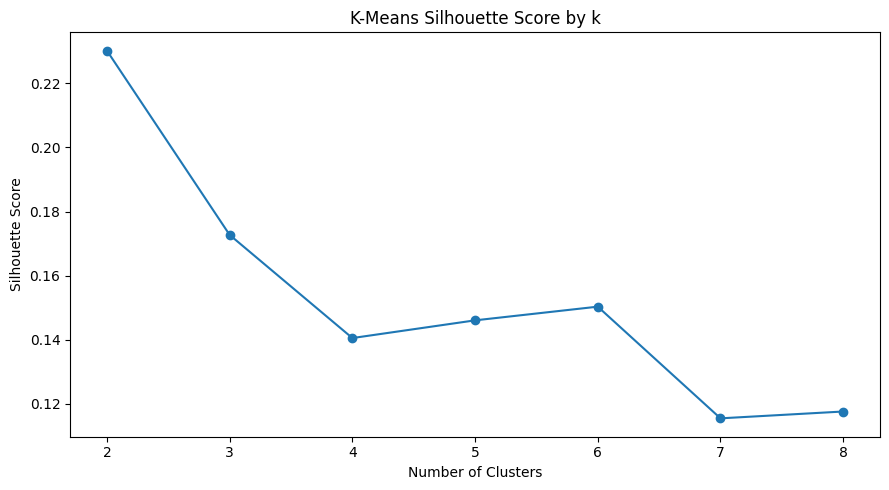

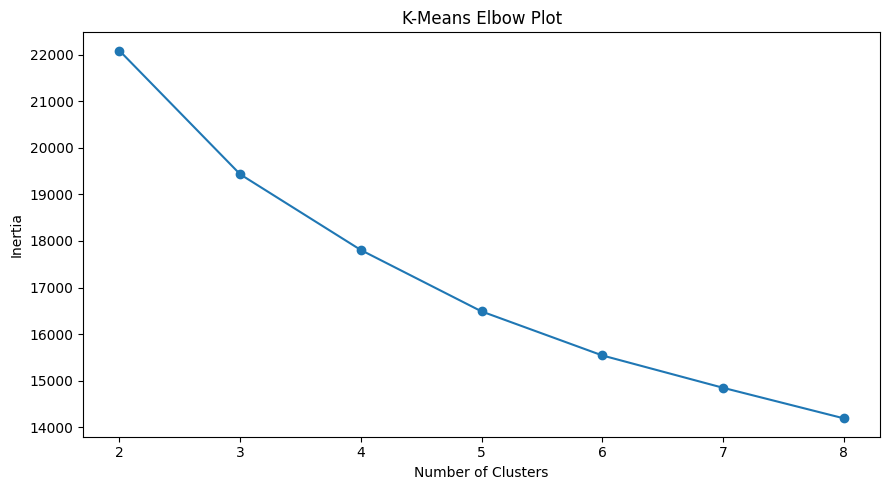

In [ ]:
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(k_df['Clusters'],k_df['Silhouette'],marker='o');ax.set_xlabel('Number of Clusters');ax.set_ylabel('Silhouette Score');ax.set_title('K-Means Silhouette Score by k');plt.tight_layout();plt.show()
plt.figure(figsize=(9,5));plt.plot(k_df['Clusters'],k_df['Inertia'],marker='o');plt.xlabel('Number of Clusters');plt.ylabel('Inertia');plt.title('K-Means Elbow Plot');plt.tight_layout();plt.show()

The highest silhouette score was 0.2301 with two clusters. I expected that increasing the number of clusters might reveal more detailed borrower groups, but the silhouette scores generally declined as additional clusters were added. This suggests that the data did not naturally separate into many distinct groups using K-Means.

Although two clusters produced the best result, the silhouette score was still relatively low. This means that the groups were not strongly separated, even after scaling the continuous variables. Selecting two clusters provided the best solution among the values tested, but it does not necessarily mean that the borrowers form two clearly defined risk categories.

## Cluster Profiles

After selecting k using silhouette score, I looked at the average income, loan amount, loan percent income, and default rate in each group. Default rate is for interpretation only; it was not used to form the clusters.

,Borrowers,Default_Rate,Average_Income,Average_Loan,Average_Loan_Percent_Income,Average_Interest_Rate
Cluster,,,,,,
0,806,0.210,89458.700,13535.484,0.183,11.392
1,2194,0.222,57291.876,8158.250,0.161,10.919


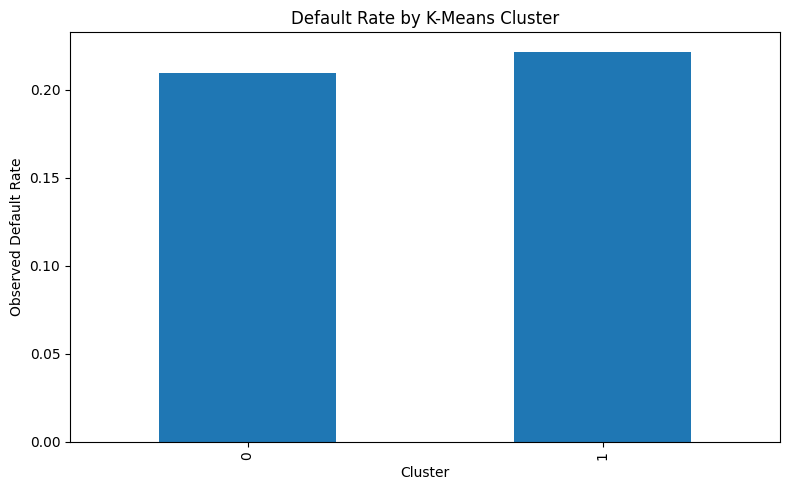

In [ ]:
kmeans=KMeans(n_clusters=best_k,random_state=42,n_init=10)
cluster_data['Cluster']=kmeans.fit_predict(cluster_matrix)
profile=cluster_data.groupby('Cluster').agg(Borrowers=('loan_status','size'),Default_Rate=('loan_status','mean'),Average_Income=('person_income','mean'),Average_Loan=('loan_amnt','mean'),Average_Loan_Percent_Income=('loan_percent_income','mean'),Average_Interest_Rate=('loan_int_rate','mean'))
display(profile.round(3))
profile['Default_Rate'].plot.bar(figsize=(8,5));plt.ylabel('Observed Default Rate');plt.title('Default Rate by K-Means Cluster');plt.tight_layout();plt.show()

Cluster 0 contained 806 borrowers with an average income of approximately $89,459 and an average loan amount of $13,535. Cluster 1 contained 2,194 borrowers with a lower average income of approximately $57,292 and an average loan amount of $8,158.

Despite these differences, the default rates were similar at approximately 21.0% and 22.2%. I expected that groups with different income and loan characteristics might also have different default rates, but that was not strongly supported by the results. K-Means appeared to separate borrowers more by financial characteristics than by observed default risk.

## Visualizing the Clusters

I used PCA to project the encoded predictors into two dimensions. This makes it easier to visualize the groups, but the plotted dimensions do not preserve all the information used by K-Means.

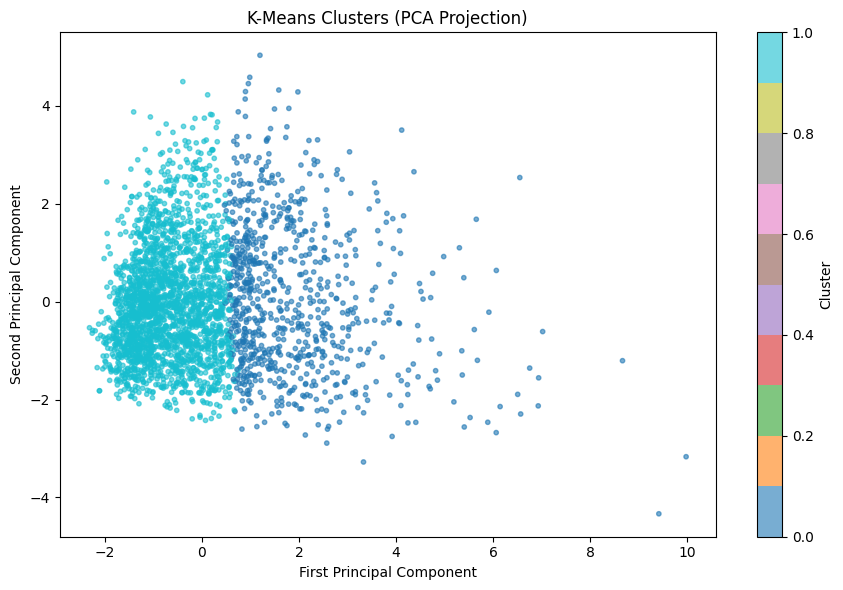

Variance explained by two components: 0.4242


In [ ]:
pca=PCA(n_components=2,random_state=42)
points=pca.fit_transform(cluster_matrix)
plt.figure(figsize=(9,6));plt.scatter(points[:,0],points[:,1],c=cluster_data['Cluster'],s=10,alpha=0.6,cmap='tab10');plt.xlabel('First Principal Component');plt.ylabel('Second Principal Component');plt.title('K-Means Clusters (PCA Projection)');plt.colorbar(label='Cluster');plt.tight_layout();plt.show()
print('Variance explained by two components:',round(pca.explained_variance_ratio_.sum(),4))

## Conclusions

I compared two through eight clusters using silhouette scores and selected two clusters because they produced the highest score of 0.2301. However, the relatively low score suggested that the borrower groups were not strongly separated.

The two clusters differed in average income and loan amount, but their default rates were similar. This was somewhat unexpected because I thought the differences in financial characteristics might also produce clearer differences in default risk.

Unlike the classification models from previous weeks, K-Means does not directly predict default. The results suggest that clustering may be useful for understanding borrower characteristics, but the groups identified here were not particularly useful for distinguishing higher-risk borrowers from lower-risk borrowers. This analysis was also limited to a reproducible sample of 3,000 observations, so the results may not fully represent the entire dataset.

In [ ]:
print('Selected k:',best_k)
print('Best silhouette:',round(k_df['Silhouette'].max(),4))
print('Lowest observed cluster default rate:',round(profile['Default_Rate'].min(),4))
print('Highest observed cluster default rate:',round(profile['Default_Rate'].max(),4))

Selected k: 2
Best silhouette: 0.2301
Lowest observed cluster default rate: 0.2097
Highest observed cluster default rate: 0.2215
